# Extension 3 — Final Persistence Test (D-52, recorded in D-53)

**Question:** how large is the default persistence forecast's error on weeks nobody had looked at?

The candidate test window (target Sundays **2026-07-05 → 2026-10-18**) was opened **exactly once**, under decision D-52, for persistence only. This notebook **reads the saved results**; it never reruns the evaluation (a run-once lock refuses that), and it reads no test-window or holdout rows.

| Section | Content |
|---|---|
| 1 | Run evidence: lock, completion record, output hashes |
| 2 | Headline error by crop and horizon, with uncertainty |
| 3 | Grade-design sensitivity |
| 4 | Error by month, and the Onion 4-week September spike |
| 5 | States: wider uncertainty and leave-one-state-out |
| 6 | Coverage and exclusions |
| 7 | Validation vs test (descriptive only) |
| 8 | The reporting-only restriction |

**Previous:** [Extension 2](Research_Extension_02_Candidate_Forecast_Experiments.ipynb) · **Next:** [Extension 4 — Conclusions](Research_Extension_04_Conclusions_and_Project_Guide.ipynb)

> **Status of this material.** Everything here is a **candidate experiment** (`candidate-prices-v1.1`, D-50), kept separate from the production Phase 1–10 pipeline. Nothing in this notebook is a production model, and nothing here changes the dashboard.

In [1]:
# Setup: locate the project root; read saved outputs only (no parquet, no network, no writes)
import hashlib, json, os, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "Notebooks" else Path.cwd()
os.chdir(PROJECT_ROOT)
pd.set_option("display.width", 180); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 140)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
C = Path("Processed_Data/candidates/datagov_prices")      # candidate data and experiments (not production)
EXP = C / "experiments"
CROPS = ["Onion", "Potato", "Wheat"]
COLORS = {"Onion": "#7b3294", "Potato": "#c2a5cf", "Wheat": "#e66101"}
print("Python", sys.version.split()[0])

Python 3.13.7


## 1. Run evidence

The runner created `RUN_LOCK.json` before reading any test row and `RUN_COMPLETED.json` after writing the outputs. Here the chain is re-checked by hashing the saved files (read-only).

In [2]:
D = EXP / "exp_candidate_v1/persistence_test_d52"
R = D / "run"
sha = lambda p: hashlib.sha256(Path(p).read_bytes()).hexdigest()
lock, done, man = (json.loads((p).read_text()) for p in (D / "RUN_LOCK.json", D / "RUN_COMPLETED.json", R / "run_manifest.json"))
checks = {"completion record matches run manifest": done["run_manifest_sha256"] == sha(R / "run_manifest.json"),
          "run manifest matches freeze": man["freeze_manifest_sha256"] == sha(D / "freeze_manifest.json") == lock["freeze_manifest_sha256"],
          "all outputs match recorded hashes": all(sha(R / f) == h for f, h in man["outputs_sha256"].items())}
print("run:", man["utc_start"], "→", man["utc_end"], "| designs:", man["designs"], "| horizons:", man["horizons"])
print("note:", man["note"])
pd.Series(checks, name="verified").to_frame()

run: 2026-10-24T14:37:24+00:00 → 2026-10-24T14:37:30+00:00 | designs: ['faq_only', 'faq_local', 'pooled'] | horizons: [1, 2, 4]
note: persistence only; skill vs persistence is 0 and not reported; reporting only, never for tuning or selection (D-52 item 10)


,verified
completion record matches run manifest,True
run manifest matches freeze,True
all outputs match recorded hashes,True


## 2. Headline error (primary design: FAQ-only)

Two 95% intervals are shown for MAE: resampling **markets** (the protocol's interval) and resampling **states** (a robustness check). Few states means a wide state interval.

In [3]:
bc = pd.read_csv(R / "by_crop.csv")
fo = bc[bc.design == "faq_only"].set_index(["Commodity", "horizon"])
fo[["n", "markets", "states", "mae", "market_mae_ci95_lo", "market_mae_ci95_hi", "state_mae_ci95_lo", "state_mae_ci95_hi",
    "rmse", "mape_pct", "median_ape_pct", "mape_unstable"]].round(1)

,,n,markets,states,mae,market_mae_ci95_lo,market_mae_ci95_hi,state_mae_ci95_lo,state_mae_ci95_hi,rmse,mape_pct,median_ape_pct,mape_unstable
Commodity,horizon,,,,,,,,,,,,
Onion,1,1048,72,8,231.3,216.1,247.7,219.4,249.3,374.3,7.6,4.3,False
Potato,1,1137,82,11,32.0,24.8,40.6,20.9,55.2,78.9,3.5,1.1,False
Wheat,1,2591,177,5,40.7,34.6,48.4,27.3,60.4,87.5,1.5,0.8,False
Onion,2,1035,68,8,387.9,364.3,411.7,362.7,402.3,571.2,12.3,9.0,False
Potato,2,1122,80,10,45.8,37.0,56.6,33.4,71.0,92.7,5.1,2.6,False
Wheat,2,2567,176,5,49.9,43.7,57.4,33.3,74.0,93.0,1.9,1.1,False
Onion,4,1023,68,8,678.8,637.4,719.3,608.4,730.6,894.5,21.0,19.6,False
Potato,4,1093,80,10,66.5,55.6,80.3,54.6,92.3,118.9,7.7,4.9,False
Wheat,4,2528,174,5,68.6,61.3,76.9,45.4,104.4,113.3,2.6,1.9,False


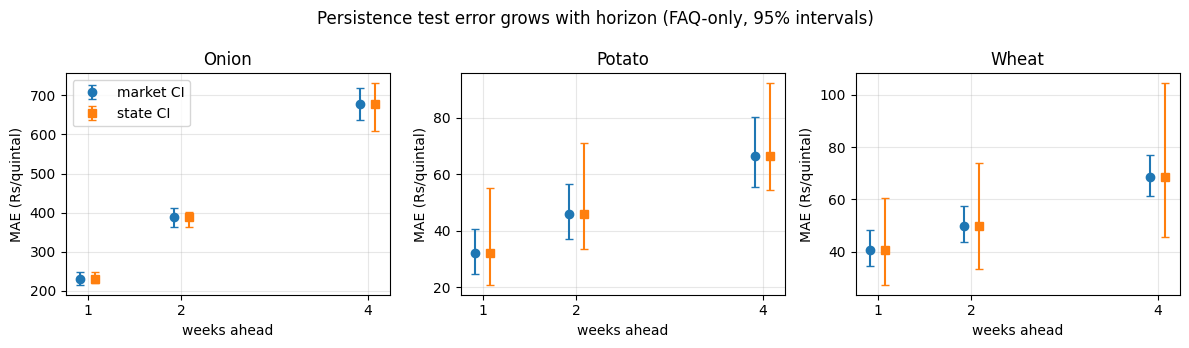

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, crop in zip(axes, CROPS):
    g = fo.loc[crop]
    ax.errorbar(g.index - 0.08, g.mae, yerr=[g.mae - g.market_mae_ci95_lo, g.market_mae_ci95_hi - g.mae], fmt="o", capsize=3, label="market CI")
    ax.errorbar(g.index + 0.08, g.mae, yerr=[g.mae - g.state_mae_ci95_lo, g.state_mae_ci95_hi - g.mae], fmt="s", capsize=3, label="state CI")
    ax.set(title=crop, xlabel="weeks ahead", xticks=[1, 2, 4], ylabel="MAE (Rs/quintal)")
axes[0].legend(); fig.suptitle("Persistence test error grows with horizon (FAQ-only, 95% intervals)"); plt.tight_layout(); plt.show()

**Reading it.** One week ahead, persistence misses Potato and Wheat by about 30–40 Rs/quintal (1–4%), but Onion by about 230 (7.6%). By 4 weeks ahead the error is about 1.7× (Wheat) to 2.9× (Onion) the 1-week error. No cell triggered the MAPE instability flag.

## 3. Grade-design sensitivity (1 week ahead)

In [5]:
bc[bc.horizon == 1].pivot(index="Commodity", columns="design", values="mae").round(1)[["faq_only", "faq_local", "pooled"]]

design,faq_only,faq_local,pooled
Commodity,,,
Onion,231.3,262.8,264.1
Potato,32.0,33.9,39.6
Wheat,40.7,40.6,40.6


Adding Local and other grades raises Onion's error (more, noisier series) and barely moves Wheat.

## 4. Error by month

The Thursday of the target week names its month. Months hold only 3–5 target weeks each.

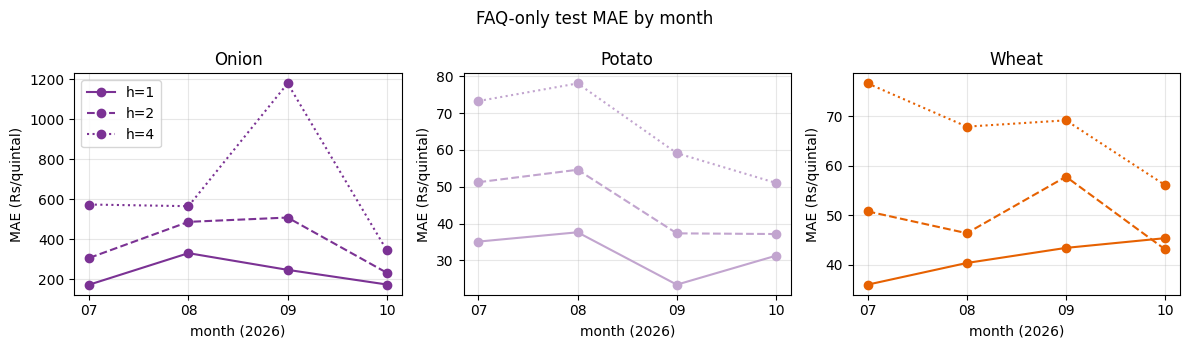

design,faq_local,faq_only,pooled
month,,,
2026-07,603.5,573.8,597.3
2026-08,679.6,565.5,664.9
2026-09,1397.4,1178.4,1361.8
2026-10,414.6,345.2,411.1


In [6]:
bm = pd.read_csv(R / "by_crop_month.csv")
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), sharex=True)
for ax, crop in zip(axes, CROPS):
    for h, ls in zip((1, 2, 4), ("-", "--", ":")):
        g = bm[(bm.design == "faq_only") & (bm.horizon == h) & (bm.Commodity == crop)]
        ax.plot(g.month.str[5:], g.mae, ls, marker="o", label=f"h={h}", color=COLORS[crop])
    ax.set(title=crop, xlabel="month (2026)", ylabel="MAE (Rs/quintal)")
axes[0].legend(); fig.suptitle("FAQ-only test MAE by month"); plt.tight_layout(); plt.show()
bm[(bm.Commodity == "Onion") & (bm.horizon == 4)].pivot(index="month", columns="design", values="mae").round(1)

**The Onion 4-week September spike.** Four-week-ahead Onion error in September (about 1,178 Rs/quintal in FAQ-only, MAPE ≈ 29%) is roughly double July–August, and it appears in every grade design. It rests on 4 target weeks, so it describes this season, not a general rule; its cause is **not** established here.

## 5. States

In [7]:
bs = pd.read_csv(R / "by_crop_state.csv")
bs[(bs.design == "faq_only") & (bs.horizon == 1) & (bs.Commodity == "Wheat")][["state", "n", "markets", "mae", "market_mae_ci95_lo", "market_mae_ci95_hi"]].round(1)

,state,n,markets,mae,market_mae_ci95_lo,market_mae_ci95_hi
19,Gujarat,120,5,46.9,38.7,66.6
20,Madhya Pradesh,938,59,61.7,47.6,79.5
21,Rajasthan,34,3,28.9,20.0,32.7
22,Uttar Pradesh,1448,106,27.6,23.6,32.1
23,West Bengal,51,4,22.7,12.1,28.3


In [8]:
lo = pd.read_csv(R / "leave_one_state_out.csv")
lo[(lo.design == "faq_only") & (lo.horizon == 1)].groupby("Commodity").agg(
    states=("left_out_state", "size"), mae_all_states=("mae_all_states", "first"), min_without_one=("mae", "min"), max_without_one=("mae", "max")).round(1)

,states,mae_all_states,min_without_one,max_without_one
Commodity,,,,
Onion,8,231.3,225.6,237.1
Potato,11,32.0,29.0,48.8
Wheat,5,40.7,28.9,57.4


Wheat's evaluated rows come from only **5 states**, dominated by Uttar Pradesh (low error) and Madhya Pradesh (high error). Dropping one of them moves Wheat MAE between about 29 and 57, which is why the state interval is so much wider than the market interval. Some state cells rest on 1–2 markets and are anecdotal.

## 6. Coverage and exclusions

In [9]:
cv = pd.read_csv(R / "coverage.csv")
print(pd.read_csv(R / "exclusions.csv").exclusion.unique())
cv[cv.design == "faq_only"].set_index(["Commodity", "horizon"])[
    ["test_rows", "excluded_rows", "evaluated_rows", "markets", "states", "target_weeks", "first_target_week", "last_target_week"]]

['not_eligible_d41_at_origin']


,,test_rows,excluded_rows,evaluated_rows,markets,states,target_weeks,first_target_week,last_target_week
Commodity,horizon,,,,,,,,
Onion,1,5897,4849,1048,72,8,16,2026-06-29,2026-10-12
Potato,1,6286,5149,1137,82,11,16,2026-06-29,2026-10-12
Wheat,1,15553,12962,2591,177,5,16,2026-06-29,2026-10-12
Onion,2,5796,4761,1035,68,8,16,2026-06-29,2026-10-12
Potato,2,6216,5094,1122,80,10,16,2026-06-29,2026-10-12
Wheat,2,15161,12594,2567,176,5,16,2026-06-29,2026-10-12
Onion,4,5720,4697,1023,68,8,16,2026-06-29,2026-10-12
Potato,4,6089,4996,1093,80,10,16,2026-06-29,2026-10-12
Wheat,4,14847,12319,2528,174,5,16,2026-06-29,2026-10-12


- Every cell covers all **16 target weeks**.
- The only exclusion reason is *not eligible at origin* (too little usable history).
- **Limitation:** a week with no observed target price never enters the model table, so it cannot appear as an exclusion. All coverage is conditional on an observed target.

## 7. Validation vs test (descriptive only)

In [10]:
val = pd.read_csv(EXP / "exp_candidate_v1/baselines_phase8_quarterly/faq_only_h1/persistence_all_eligible_rows.csv")
v = val.pivot(index="Commodity", columns="quarter", values="mae")
v["test (Jul–Oct)"] = fo.xs(1, level="horizon").mae
v.round(1)

quarter,2026Q1,2026Q2,test (Jul–Oct)
Commodity,,,
Onion,94.7,99.7,231.3
Potato,57.7,41.1,32.0
Wheat,41.5,34.2,40.7


Onion's test error is more than twice its validation error; Potato's is lower; Wheat's is similar. The periods differ in season, rows and markets, so this is a **description, not evidence that forecasting got worse**.

## 8. Reporting-only restriction

The test window is now **consumed**. These results must not be used to tune, compare or select models, features, thresholds or populations (D-52 item 10). Any future learned price or arrivals model needs a fresh evaluation period with data after 2026-10-20.